# 03 — Signatures · Griffiths et al. 2021 (Breast Cancer)

Score Gast / pSom / Crest with the union control pool and read their **geography** on the manifold. Signature UMAPs show **raw** per-cell scores (deliverable rule). This notebook decides **Gate 2**.

In [1]:
import os, glob, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
name=os.path.split(os.getcwd())[1]
pth=os.path.join('..', '..', '..', '..')
pth_in=os.path.join(pth,'data','cancer', 'vertebrate', 'CCCA', 'claude','Breast',name)
pth_feat=os.path.join(pth,'data','features','biomart')
pth_fig=os.path.join(pth,'figures', 'mesencontext', 'claude','Breast',name)
pth_cb=os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb,exist_ok=True)

In [1]:
adata=sc.read_h5ad(os.path.join(pth_in,'manifold.h5ad')); adata

### score_genes — Gast / pSom / Crest with the union control pool

In [1]:
raw=adata.raw.to_adata(); raw.obsm=adata.obsm; raw.obs=adata.obs.copy()
feat_fn=sorted(glob.glob(os.path.join(pth_feat,'*.csv')))
get_src=lambda fn: os.path.split(fn)[1].replace('.csv','')
feat={get_src(fn):pd.read_csv(fn).hsapiens.dropna().drop_duplicates() for fn in feat_fn}
gref=feat['union'][feat['union'].isin(raw.var_names)]
namemap={'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,nm in namemap.items():
    g=feat[src][feat[src].isin(raw.var_names)]
    sc.tl.score_genes(raw,gene_list=g,score_name=nm,ctrl_as_ref=False,gene_pool=gref,random_state=1234)
    adata.obs[nm]=raw.obs[nm].values; print(nm,'recovered',g.size,'genes, mean',round(float(adata.obs[nm].mean()),4))

Gast recovered 76 genes, mean -0.0215
pSom recovered 88 genes, mean -0.0519
Crest recovered 100 genes, mean 0.0212


### Smoothed scores for reading geography (raw is shown in the deliverables)
kNN-connectivity averaging denoises the 80-100-gene module scores for correlation reads; the saved signature UMAPs below plot the **raw** per-cell scores.

In [1]:
A=adata.obsp['connectivities']; deg=np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for c0 in ['Gast','pSom','Crest']: adata.obs[c0+'_sm']=np.asarray(A@adata.obs[c0].values).ravel()/deg
o=adata.obs
print('smoothed corr Gast-pSom',round(o[['Gast_sm','pSom_sm']].corr().iloc[0,1],3),
      '| Gast-Crest',round(o[['Gast_sm','Crest_sm']].corr().iloc[0,1],3),
      '| pSom-Crest',round(o[['pSom_sm','Crest_sm']].corr().iloc[0,1],3))

smoothed corr Gast-pSom -0.205 | Gast-Crest -0.517 | pSom-Crest -0.551


### Gate 2 test — is there a Gast/pSom hub / overlap with terminal Crest?
GO templates (spec §1-2) require Gast/pSom to **overlap / co-vary** (a hub, or the non-branching co-variation case) with Crest as an inverse/terminal gradient. Test co-location of the high-score populations and whether the pattern survives controlling for the ribosomal (lobe) axis.

In [1]:
gh=o.Gast_sm>o.Gast_sm.quantile(0.8); ph=o.pSom_sm>o.pSom_sm.quantile(0.8)
jac=lambda a,b:(a&b).sum()/(a|b).sum()
print('Gast-hi & pSom-hi Jaccard',round(jac(gh,ph),3))
print('co-high Gast&pSom fraction',round((o.Gast_sm.gt(o.Gast_sm.quantile(0.9))&o.pSom_sm.gt(o.pSom_sm.quantile(0.9))).mean(),3),'(chance 0.01 at 10%x10%; observed below independence)')
# control for ribosomal (dominant lobe) axis
ribo=[g for g in raw.var_names if g.startswith(('RPL','RPS'))]
o['ribo']=np.asarray(raw[:,ribo].X.mean(1)).ravel()
resid=lambda y,x:y-np.polyval(np.polyfit(x,y,1),x)
gr=resid(o.Gast.values,o.ribo.values); pr=resid(o.pSom.values,o.ribo.values)
print('partial corr Gast-pSom | ribosomal =', round(np.corrcoef(gr,pr)[0,1],3),'(still negative -> no overlap)')

Gast-hi & pSom-hi Jaccard 0.088
co-high Gast&pSom fraction 0.007 (chance 0.01 at 10%x10%; observed below independence)
partial corr Gast-pSom | ribosomal = -0.145 (still negative -> no overlap)


**Gate 2 = NO-GO.** Gast and pSom do not overlap (Jaccard ~0.09; co-high below the independence expectation) and stay negatively related even after removing the ribosomal axis; there is no convergence hub and no two-arm divergence. Crest opposes the combined Gast/pSom score (~ -0.85) but a lone (Gast v pSom)-vs-Crest anti-correlation, with Gast/pSom marking distinct housekeeping/proliferation lobes and not organising the trajectory (|pseudotime rho| <= 0.22), does not match either GO template. Gate 3 = NA (not branching). Per spec §6 no 04_correlation / 05_modules are produced; the unconditional EMT-TF step follows as **04**.

### Signature UMAPs (RAW per-cell scores) — Gast / pSom / Crest

<string>:9: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.


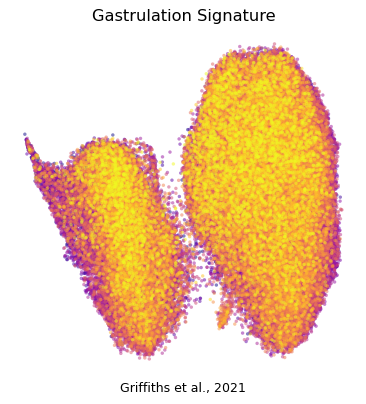

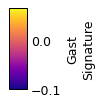

In [1]:
key,short,title='Gast','Gast','Gastrulation Signature'
v=adata.obs[key]; vmin,vmax=np.percentile(v,2),np.percentile(v,98)
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata,color=key,cmap='plasma',alpha=.5,size=30,colorbar_loc=None,frameon=False,show=False,ax=ax,vmin=vmin,vmax=vmax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title(title,size=13)
ax.text(.5,-.05,'Griffiths et al., 2021',ha='center',transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,short+'_signature.pdf'),bbox_inches='tight')
figc=plt.figure(figsize=(.66,1)); cax=figc.add_axes([.35,.05,.3,.9])
cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
cb.set_label(short+'\nSignature'); cb.solids.set_alpha(1)
figc.savefig(os.path.join(pth_cb,short+'_colorbar.pdf'),bbox_inches='tight')

<string>:9: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.


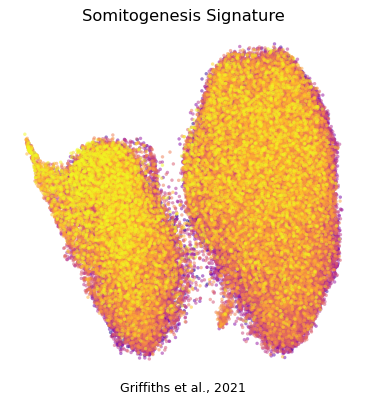

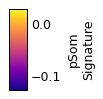

In [1]:
key,short,title='pSom','pSom','Somitogenesis Signature'
v=adata.obs[key]; vmin,vmax=np.percentile(v,2),np.percentile(v,98)
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata,color=key,cmap='plasma',alpha=.5,size=30,colorbar_loc=None,frameon=False,show=False,ax=ax,vmin=vmin,vmax=vmax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title(title,size=13)
ax.text(.5,-.05,'Griffiths et al., 2021',ha='center',transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,short+'_signature.pdf'),bbox_inches='tight')
figc=plt.figure(figsize=(.66,1)); cax=figc.add_axes([.35,.05,.3,.9])
cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
cb.set_label(short+'\nSignature'); cb.solids.set_alpha(1)
figc.savefig(os.path.join(pth_cb,short+'_colorbar.pdf'),bbox_inches='tight')

<string>:9: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.


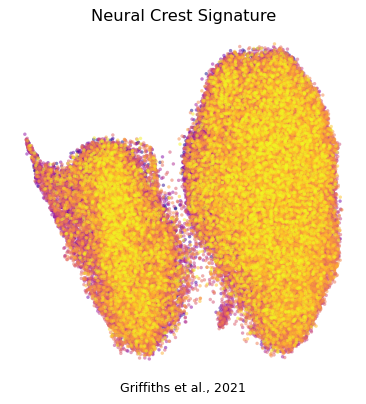

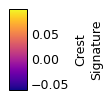

In [1]:
key,short,title='Crest','Crest','Neural Crest Signature'
v=adata.obs[key]; vmin,vmax=np.percentile(v,2),np.percentile(v,98)
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata,color=key,cmap='plasma',alpha=.5,size=30,colorbar_loc=None,frameon=False,show=False,ax=ax,vmin=vmin,vmax=vmax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title(title,size=13)
ax.text(.5,-.05,'Griffiths et al., 2021',ha='center',transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,short+'_signature.pdf'),bbox_inches='tight')
figc=plt.figure(figsize=(.66,1)); cax=figc.add_axes([.35,.05,.3,.9])
cb=plt.colorbar(ax.collections[0],cax=cax); cb.ax.tick_params(which='both',size=0)
cb.set_label(short+'\nSignature'); cb.solids.set_alpha(1)
figc.savefig(os.path.join(pth_cb,short+'_colorbar.pdf'),bbox_inches='tight')

In [1]:
adata.write(os.path.join(pth_in,'signatures.h5ad')); print('saved signatures.h5ad')

saved signatures.h5ad
